In [44]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import random
import random
import math

import matplotlib.pyplot as plt
from PIL import Image

from collections import Counter

# Tampilan plot
plt.rcParams["figure.figsize"] = (8,6)

In [45]:
DATA_DIR = Path("../data")

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

print(TRAIN_DIR)
print(TEST_DIR)

..\data\train
..\data\test


In [46]:
print(os.listdir(TRAIN_DIR))

['0_Recyclable', '1_Electronic', '2_Organic']


In [47]:
class_counts = {}

for cls in os.listdir(TRAIN_DIR):
    cls_path = TRAIN_DIR / cls
    
    if cls_path.is_dir():
        class_counts[cls] = len(os.listdir(cls_path))

class_counts

{'0_Recyclable': 9999, '1_Electronic': 3961, '2_Organic': 12567}

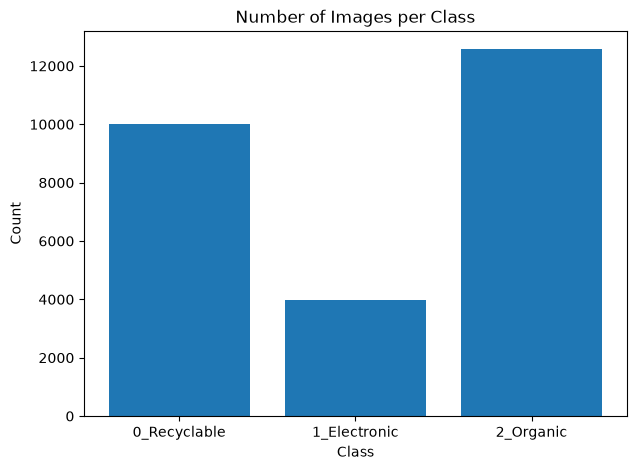

In [48]:
plt.figure(figsize=(7,5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

In [49]:
total_images = sum(class_counts.values())

print(f"Total Training Images : {total_images}")

Total Training Images : 26527


In [50]:
test_images = os.listdir(TEST_DIR)

print("Total Test Images :", len(test_images))

Total Test Images : 1458


In [51]:
sizes = []

broken_files = []

for cls in TRAIN_DIR.iterdir():

    if not cls.is_dir():
        continue

    for file in cls.glob("*"):

        try:

            if not file.exists():
                broken_files.append(file)
                continue

            with Image.open(file) as img:

                sizes.append({
                    "class": cls.name,
                    "file": file.name,
                    "width": img.width,
                    "height": img.height
                })

        except Exception:

            broken_files.append(file)

In [52]:
size_df = pd.DataFrame(sizes)

size_df.describe()

,width,height
count,26525.000000,26525.000000
mean,304.916833,250.219793
std,417.929463,342.709310
min,51.000000,69.000000
25%,220.000000,174.000000
50%,254.000000,194.000000
75%,276.000000,225.000000
max,8000.000000,6000.000000


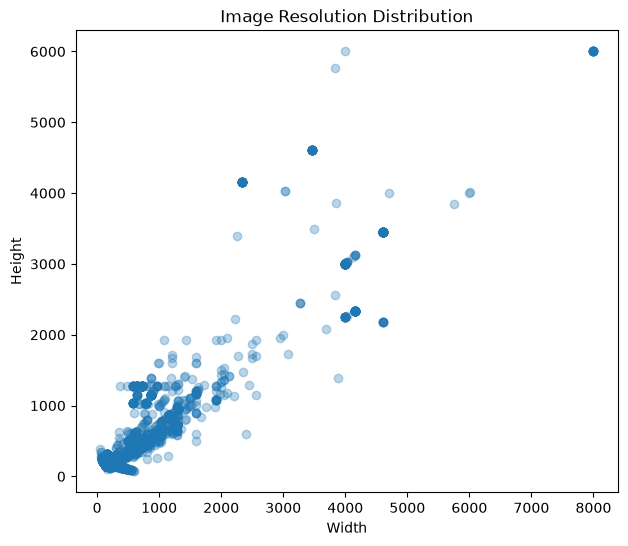

In [53]:
plt.figure(figsize=(7,6))

plt.scatter(
    size_df["width"],
    size_df["height"],
    alpha=0.3
)

plt.xlabel("Width")

plt.ylabel("Height")

plt.title("Image Resolution Distribution")

plt.show()

In [54]:
print("Broken Files :", len(broken_files))
for f in broken_files:
    print(f)

Broken Files : 2
..\data\train\1_Electronic\1.tumpukan-e-limbah-yang-kacau-dari-laptop-dan-suku-cadang-komputer-yang-dibuang-representasi-visual-yang-luar-biasa-dari-masalah-limbah-elektronik-yang-berkembang-dan-kebutuhan-akan-solusi-daur-ulang-berkelanjutan_73523-11403.jpg
..\data\train\1_Electronic\64.dampak-lingkungan-dari-ewaste-tangkap-konsekuensi-lingkungan-dari-pembuangan-ewaste-yang-tidak-tepat-seperti-perangkat-elektronik-yang-mengeluarkan-bahan-kimia-beracun-ke-dalam-tanah-dan-saluran-air-di-lokasi-pembuangan-ilegal_997534-43151.jpg


In [80]:
from pathlib import Path

folder = Path(r"D:\poetri\data\train\1_Electronic")

for f in folder.iterdir():
    if "tumpukan" in f.name.lower():
        print(f.name)

        try:
            print("Size:", f.stat().st_size)
        except Exception as e:
            print(e)

        print("-"*50)

1.tumpukan-e-limbah-yang-kacau-dari-laptop-dan-suku-cadang-komputer-yang-dibuang-representasi-visual-yang-luar-biasa-dari-masalah-limbah-elektronik-yang-berkembang-dan-kebutuhan-akan-solusi-daur-ulang-berkelanjutan_73523-11403.jpg
[WinError 3] The system cannot find the path specified: 'D:\\poetri\\data\\train\\1_Electronic\\1.tumpukan-e-limbah-yang-kacau-dari-laptop-dan-suku-cadang-komputer-yang-dibuang-representasi-visual-yang-luar-biasa-dari-masalah-limbah-elektronik-yang-berkembang-dan-kebutuhan-akan-solusi-daur-ulang-berkelanjutan_73523-11403.jpg'
--------------------------------------------------
1_tumpukan.jpg
Size: 100793
--------------------------------------------------


In [55]:
size_df.groupby(
    ["width","height"]
).size().sort_values(
    ascending=False
).head(15)

width  height
225    225       4240
150    150       2665
275    183       2567
259    194       1728
300    168        945
183    275        497
194    259        366
276    183        352
299    168        347
284    177        225
224    224        204
274    184        200
318    159        195
260    194        174
290    174        162
dtype: int64

In [56]:
size_df["ratio"] = (
    size_df["width"] /
    size_df["height"]
)

size_df["ratio"].describe()

count    26525.000000
mean         1.278172
std          0.452291
min          0.133159
25%          1.000000
50%          1.255000
75%          1.502732
max          8.695652
Name: ratio, dtype: float64

In [57]:
def show_random_images(class_name, n=15):

    folder = TRAIN_DIR / class_name

    files = random.sample(list(folder.glob("*")), n)

    cols = 5
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(15, 3*rows))

    axes = axes.flatten()

    for ax, file in zip(axes, files):

        with Image.open(file) as img:

            img.thumbnail((256,256))

            ax.imshow(img.copy())

        ax.set_title(file.name[:15], fontsize=7)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

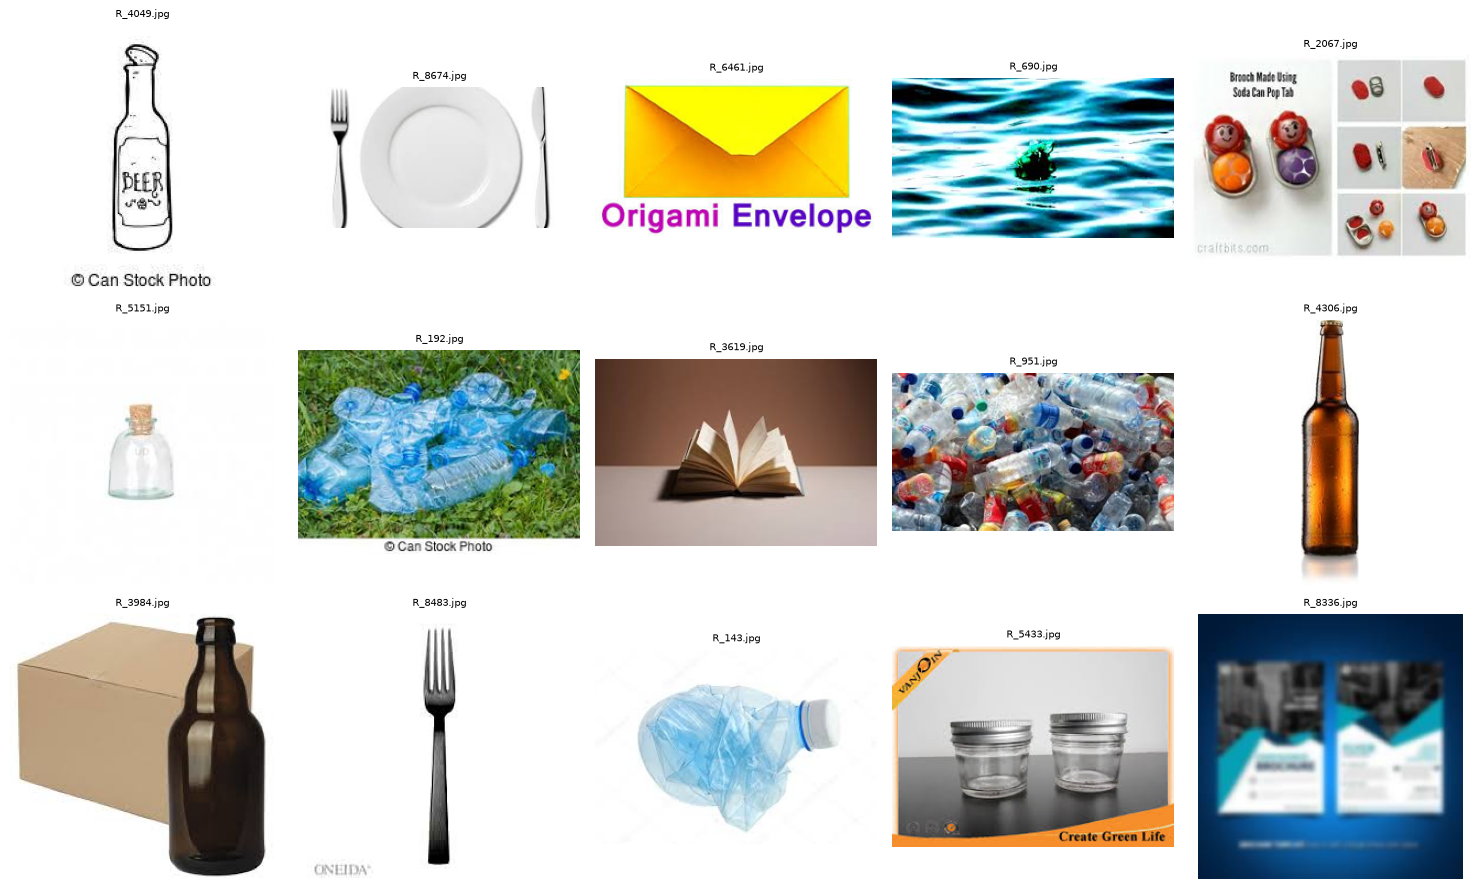

In [58]:
show_random_images("0_Recyclable")

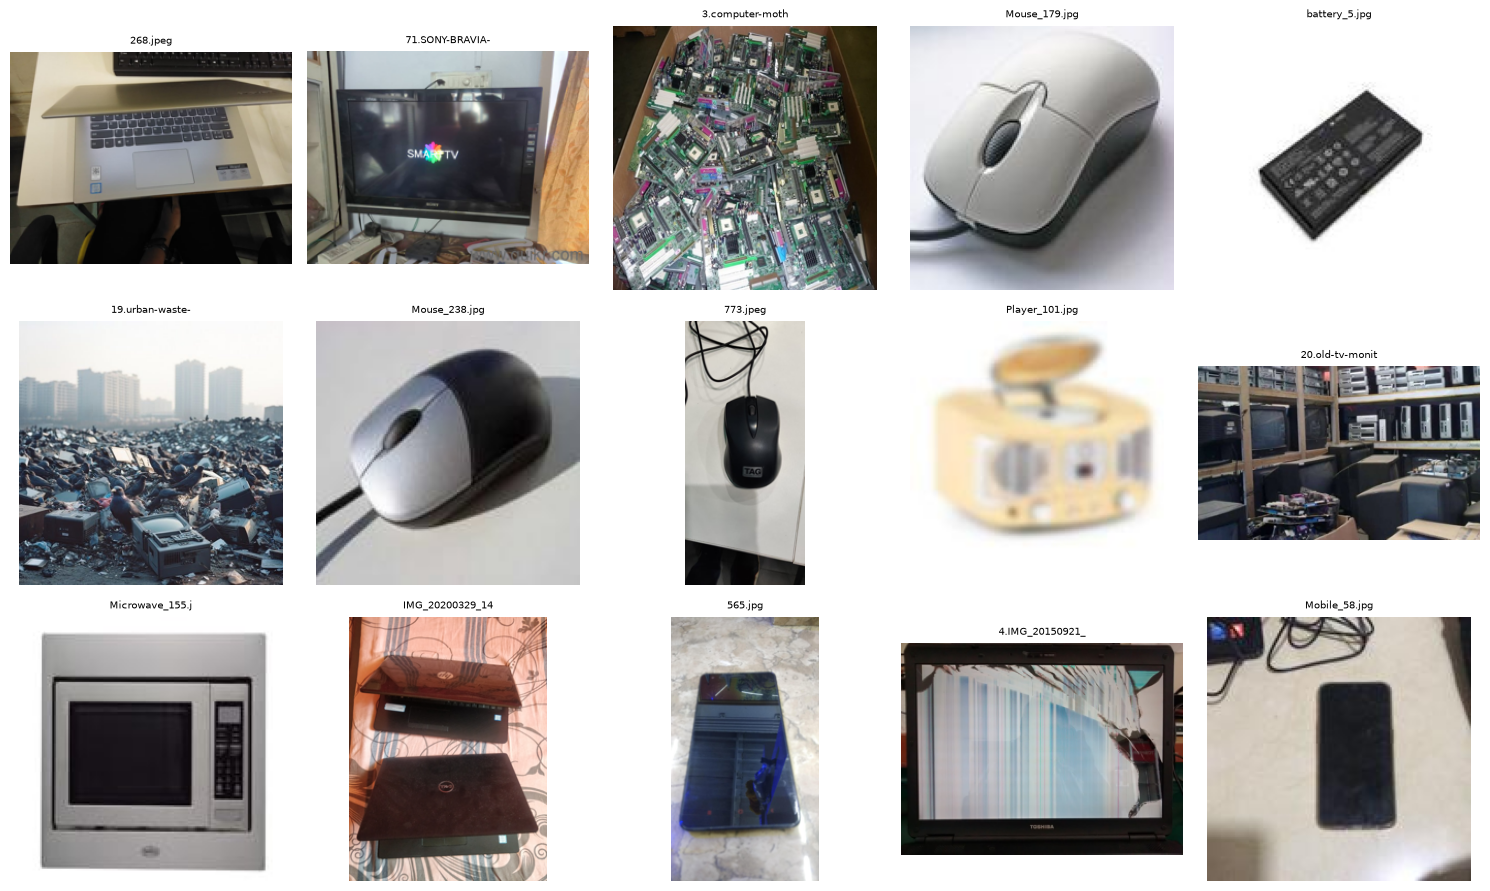

In [59]:
show_random_images("1_Electronic")

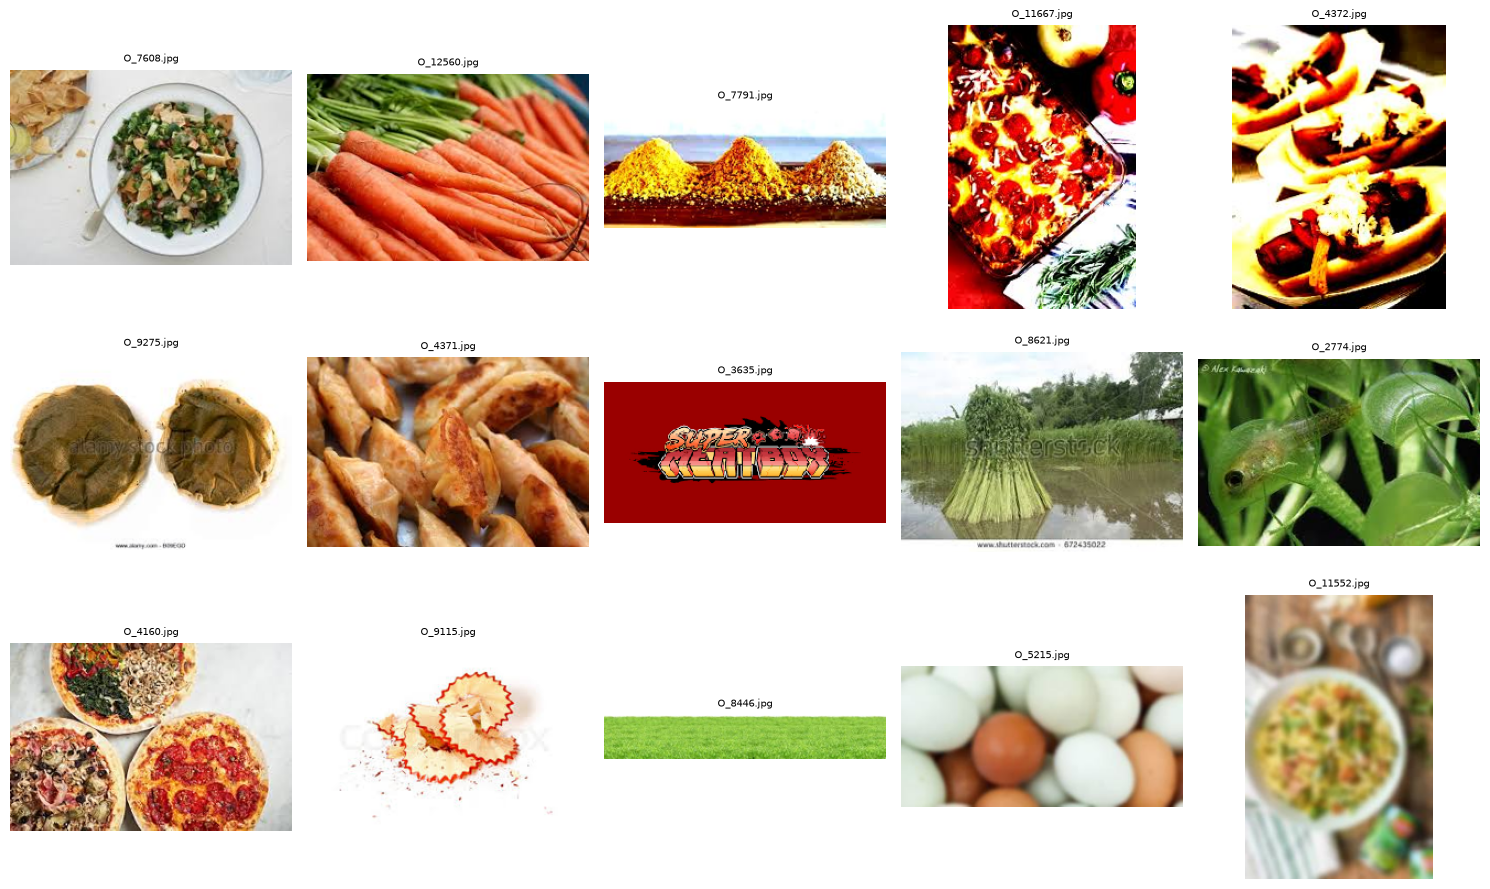

In [60]:
show_random_images("2_Organic")

In [61]:
size_df.groupby("class")[["width","height"]].describe()

width                                                       \
                count        mean          std    min    25%    50%    75%   
class                                                                        
0_Recyclable   9999.0  242.278028    44.344578   56.0  224.0  225.0  274.0   
1_Electronic   3959.0  604.719121  1026.484277  150.0  150.0  150.0  648.0   
2_Organic     12567.0  260.308586    42.455091   51.0  225.0  263.0  279.0   

                       height                                               \
                 max    count        mean         std    min    25%    50%   
class                                                                        
0_Recyclable   569.0   9999.0  211.659866   34.154425   88.0  183.0  224.0   
1_Electronic  8000.0   3959.0  515.121748  835.496417  113.0  150.0  150.0   
2_Organic      600.0  12567.0  197.447760   32.156110   69.0  179.0  190.0   

                             
                75%     max  
class                        
0_Recyclable  225.0   346.0  
1_Electronic  533.0  6000.0  
2_Organic     225.0   383.0

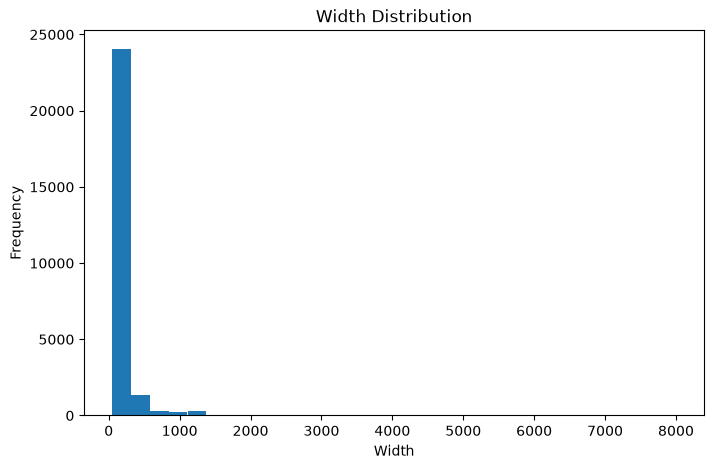

In [62]:
plt.figure(figsize=(8,5))

plt.hist(
    size_df["width"],
    bins=30
)

plt.xlabel("Width")
plt.ylabel("Frequency")
plt.title("Width Distribution")

plt.show()

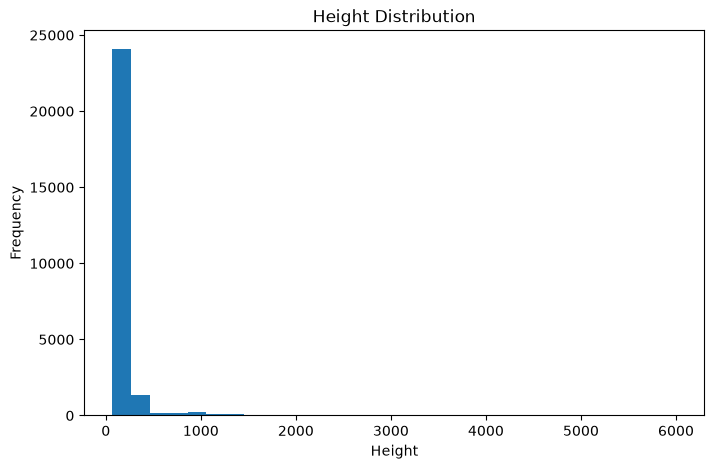

In [63]:
plt.figure(figsize=(8,5))

plt.hist(
    size_df["height"],
    bins=30
)

plt.xlabel("Height")
plt.ylabel("Frequency")
plt.title("Height Distribution")

plt.show()

In [64]:
extensions = []

for folder in TRAIN_DIR.iterdir():

    if not folder.is_dir():
        continue

    for file in folder.glob("*"):

        extensions.append(file.suffix.lower())

Counter(extensions)

Counter({'.jpg': 26049, '.jpeg': 430, '.png': 48})

In [65]:
file_sizes = []

for folder in TRAIN_DIR.iterdir():

    if not folder.is_dir():
        continue

    for file in folder.glob("*"):

        if file.exists():

            file_sizes.append(file.stat().st_size / 1024)

file_sizes = pd.Series(file_sizes)

file_sizes.describe()

count    26525.000000
mean        47.721304
std        471.266589
min          0.771484
25%          4.785156
50%          7.639648
75%         11.498047
max      19262.674805
dtype: float64

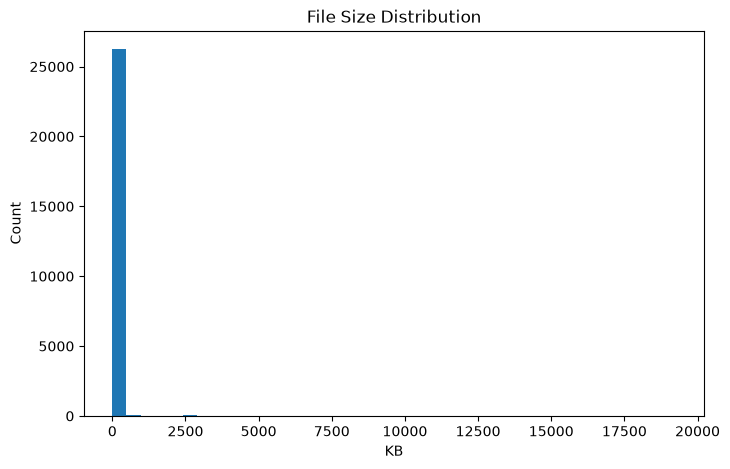

In [66]:
plt.figure(figsize=(8,5))

plt.hist(
    file_sizes,
    bins=40
)

plt.xlabel("KB")
plt.ylabel("Count")
plt.title("File Size Distribution")

plt.show()

In [67]:
smallest = size_df.sort_values(
    ["width","height"]
).head(10)

smallest

,class,file,width,height,ratio
25578,2_Organic,O_9147.jpg,51,383,0.133159
8431,0_Recyclable,R_8588.jpg,56,346,0.161850
22954,2_Organic,O_6786.jpg,56,347,0.161383
3675,0_Recyclable,R_4306.jpg,65,298,0.218121
3306,0_Recyclable,R_3975.jpg,70,277,0.252708
3629,0_Recyclable,R_4265.jpg,71,272,0.261029
3417,0_Recyclable,R_4074.jpg,72,269,0.267658
653,0_Recyclable,R_1587.jpg,72,270,0.266667
3377,0_Recyclable,R_4038.jpg,73,264,0.276515
3559,0_Recyclable,R_4201.jpg,73,265,0.275472


In [68]:
largest = size_df.sort_values(
    ["width","height"],
    ascending=False
).head(10)

largest

,class,file,width,height,ratio
11306,1_Electronic,Copy of IMG_20200328_214915.jpg,8000,6000,1.333333
11307,1_Electronic,Copy of IMG_20200328_214955.jpg,8000,6000,1.333333
11310,1_Electronic,Copy of IMG_20200328_215118.jpg,8000,6000,1.333333
11311,1_Electronic,Copy of IMG_20200328_221604.jpg,8000,6000,1.333333
11312,1_Electronic,Copy of IMG_20200328_221613.jpg,8000,6000,1.333333
11313,1_Electronic,Copy of IMG_20200328_221622.jpg,8000,6000,1.333333
11314,1_Electronic,Copy of IMG_20200328_221706.jpg,8000,6000,1.333333
11315,1_Electronic,Copy of IMG_20200328_221715.jpg,8000,6000,1.333333
11316,1_Electronic,Copy of IMG_20200328_222043.jpg,8000,6000,1.333333
11317,1_Electronic,Copy of IMG_20200328_222053.jpg,8000,6000,1.333333
